In [8]:
import os
import sys

# Move up one directory from 'notebooks' to 'root_dir' and add it to python path
root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm

from src.pc_layer import PCLayer
from src.pc_trainer import PCTrainer

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "mps")
print(f'using {device}')

using mps


In [9]:
# data parameters
mean = 1.               
variance = 5.              
batch_size = 256    
nm_batches = 150        

# generate data
data = [mean + np.sqrt(variance)*torch.randn(batch_size, 1) for i in range(nm_batches)]

In [10]:
class BiasLayer(nn.Module):
    def __init__(self, out_features):
        super(BiasLayer, self).__init__()
        self.bias = nn.Parameter(torch.Tensor(1,out_features), requires_grad=True)
        nn.init.constant_(self.bias, 0.0)

    def forward(self, x):
        return torch.zeros_like(x) + self.bias  # return the prior mean \mu with the same shape as the input x to make sure the batch size is the same

In [11]:
latent_size = 1     # number of latent states in latent layer
output_size = 1     # number of dimensions in data 
loss_fn = lambda output, _target: 0.5*(output - _target).pow(2).sum()  # loss function is mean squared error

mcpc_model = nn.Sequential(
    BiasLayer(latent_size),
    PCLayer(),
    nn.Linear(latent_size, output_size, bias=False),
)
mcpc_model.train();

In [12]:
class SGDLD(optim.SGD):
    def __init__(self, params, lr=0.01, weight_decay=0, noise_var=1.):
        super(SGDLD, self).__init__(params, lr, weight_decay)
        self.noise_var = noise_var

    def step(self, closure=None):
        super(SGDLD, self).step(closure)

        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                p.data.add_(np.sqrt(2*self.noise_var*group['lr'])*torch.randn_like(p))

In [15]:
T_mixing = 250                      # number of inference iterations without parameter gradient accumulation
T_sampling = 1                      # number of inference iterations without parameter gradient accumulation
update_x_at = 'all'                 # update latent state x at every iteration
optimizer_x_fn = SGDLD              # noisy optimizer for latent state x
optimizer_x_kwargs = {'lr': 0.01}   # optimizer parameters for latent state x
update_p_at = 'last'                # update parameters p at the last iteration
optimizer_p_fn = optim.Adam         # optimizer for parameters p
optimizer_p_kwargs = {'lr': 0.1}    # optimizer parameters for p
plot_progress_at = []               # plot progress every inference iterations


trainer = PCTrainer(mcpc_model, 
    T = T_mixing+T_sampling, 
    update_x_at = update_x_at, 
    optimizer_x_fn = optimizer_x_fn,
    optimizer_x_kwargs = optimizer_x_kwargs,
    update_p_at = update_p_at,   
    optimizer_p_fn = optimizer_p_fn,
    optimizer_p_kwargs = optimizer_p_kwargs,
    plot_progress_at= plot_progress_at
)

In [16]:
n_epochs = 5

for idx_epoch in range(n_epochs):
    for i, y in enumerate(pbar := tqdm(data, desc=f"Epoch: {idx_epoch+1}")):
        pseudo_input = torch.zeros(batch_size, 1) # pseudo input data, This data is only used to set the batch_size of the PCLayers
        trainer.train_on_batch(
            inputs=pseudo_input, 
            loss_fn=loss_fn, 
            loss_fn_kwargs={'_target':y}
        )
    pbar.set_description(f"Epoch: {idx_epoch+1}")

Epoch: 5: 100%|██████████| 150/150 [00:04<00:00, 32.46it/s]


In [18]:
model_generation = nn.Sequential(
    mcpc_model[:],
    PCLayer() 
)
model_generation.train()    

# setup trainer for generation with large T
generation_trainer = PCTrainer(model_generation, 
    T = 10000, 
    update_x_at = update_x_at, 
    optimizer_x_fn = optimizer_x_fn,
    optimizer_x_kwargs = optimizer_x_kwargs,
    update_p_at = "never",                      # the model is already trained
    optimizer_p_fn = optimizer_p_fn,
    optimizer_p_kwargs = optimizer_p_kwargs,
    plot_progress_at= plot_progress_at
)

In [19]:
nm_samples = 10240
pseudo_input = torch.zeros(nm_samples, 1) 
generation_trainer.train_on_batch(inputs=pseudo_input, is_log_progress=False, is_return_results_every_t=False, is_checking_after_callback_after_t=False)

samples = model_generation[-1]._x.detach().cpu().numpy()

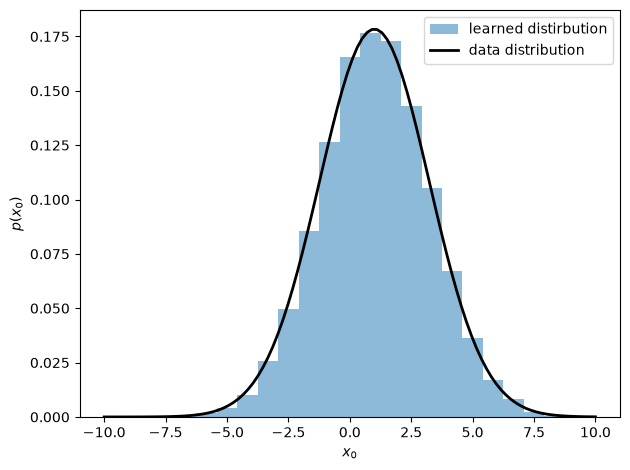

In [20]:
plt.hist(samples, bins=20, alpha=0.5, density=True, label="learned distirbution")
x = np.linspace(-10,10,100)
plt.plot(x, 1/np.sqrt(2*np.pi*variance)*np.exp(-0.5*(x - mean)**2/variance), "k", linewidth=2, label="data distribution")
plt.xlabel(r"$x_0$")
plt.ylabel(r"$p(x_0)$")
plt.legend()
plt.tight_layout()